<a href="https://colab.research.google.com/github/eduardozurek/ia/blob/main/_008_redes_neuronales_artificiales/02_MLP_EZ_datos_sinteticos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Perceptrón multicapa: clasificación de datos sintéticos
**Eduardo Zurek — Clase de Inteligencia Artificial**

Nueva versión basada exclusivamente en los datos de la primera celda de `MLP_EZ_optimizado.ipynb`.
No requiere archivos de imágenes ni datos externos. Los resultados se presentan en tablas.

Objetivos:
- Comprender qué efecto tiene la activación de la capa oculta.
- Comparar configuraciones manteniendo constantes los demás hiperparámetros.
- Separar entrenamiento, selección del modelo y evaluación final.
- Interpretar el desempeño ante el desbalance de clases y el solapamiento.

Ejecutar las celdas en orden, desde un kernel reiniciado. Dependencias: NumPy, pandas y scikit-learn.
Si faltan, ejecutar en una celda: `%pip install numpy pandas scikit-learn`.


In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import sklearn
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, cohen_kappa_score, log_loss, brier_score_loss,
    confusion_matrix, classification_report,
)

SEMILLA = 42
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
print("Versiones:", "NumPy", np.__version__, "pandas", pd.__version__,
      "scikit-learn", sklearn.__version__)


Versiones: NumPy 2.1.3 pandas 2.2.3 scikit-learn 1.6.1


## 1. Generación del conjunto original

Se conserva la secuencia aleatoria de la primera celda original. `n_red = 500` indica puntos **por centro**;
`n_black = 500` indica el total de puntos negros. Por tanto, hay 2000 observaciones:
1500 rojas (clase 1) y 500 negras (clase 0).

`radio_rojo = 0.05` es el nombre original, pero su significado en `np.random.normal` es una
**desviación estándar**, no un radio máximo. Los puntos negros se rechazan si están a menos de
0,1 de cualquiera de los centros. Los rojos pueden salir de esos círculos; por ello existe
solapamiento entre las distribuciones de las clases.


In [2]:
np.random.seed(SEMILLA)
n_red = 500
n_black = 500
centros_rojos = np.array([[0.2, 0.2], [0.7, 0.2], [0.45, 0.6]])
radio_rojo = 0.05
radio_exclusion = 0.1
desv_negro = 0.15

X_red, y_red = [], []
for centro in centros_rojos:
    puntos = np.random.normal(loc=centro, scale=radio_rojo, size=(n_red, 2))
    X_red.append(puntos)
    y_red.append(np.ones(n_red))
X_red = np.vstack(X_red)
y_red = np.hstack(y_red)

X_black = []
while len(X_black) < n_black:
    centro = centros_rojos[np.random.choice(len(centros_rojos))]
    punto = np.random.normal(loc=centro, scale=desv_negro, size=(1, 2))[0]
    if not np.any(np.linalg.norm(punto - centros_rojos, axis=1) < radio_exclusion):
        X_black.append(punto)
X_black = np.array(X_black)
y_black = np.zeros(len(X_black))

X = np.vstack([X_red, X_black])
y = np.hstack([y_red, y_black])
X, y = shuffle(X, y, random_state=SEMILLA)
y = y.astype(int)  # Cambia el tipo, no las etiquetas ni su orden.
assert X.shape == (2000, 2) and np.isfinite(X).all()
print(pd.DataFrame({"Clase": [0, 1], "Color": ["Negro", "Rojo"],
                    "Cantidad": np.bincount(y),
                    "Porcentaje": 100 * np.bincount(y) / len(y)}).to_string(index=False))
print("\nPrimeras cinco observaciones:")
print(pd.DataFrame({"x1": X[:5, 0], "x2": X[:5, 1], "clase": y[:5]}).to_string(index=False))


 Clase Color  Cantidad  Porcentaje
     0 Negro       500        25.0
     1  Rojo      1500        75.0

Primeras cinco observaciones:
      x1       x2  clase
0.073046 0.112264      0
0.135979 0.287740      1
0.492409 0.538374      1
0.675847 0.207340      1
0.464032 0.687931      1


## 2. Entrenamiento, validación y prueba

Usamos particiones estratificadas: 60 % para entrenamiento, 20 % para validación y 20 % para prueba.
La validación selecciona la activación. La prueba se consulta solamente después de esa selección.
Los puntos uniformes aleatorios del cuaderno anterior no se usan como prueba: no tienen etiquetas observadas.

La generación normal no está limitada al cuadrado [0, 1] × [0, 1]. Conservamos todos los puntos,
sin recortarlos ni cambiar sus distribuciones.


In [3]:
indices = np.arange(len(y))
i_desarrollo, i_test = train_test_split(
    indices, test_size=0.20, stratify=y, random_state=SEMILLA)
i_train, i_val = train_test_split(
    i_desarrollo, test_size=0.25, stratify=y[i_desarrollo], random_state=SEMILLA)
X_train, y_train = X[i_train], y[i_train]
X_val, y_val = X[i_val], y[i_val]
X_test, y_test = X[i_test], y[i_test]
assert not (set(i_train) & set(i_val) or set(i_train) & set(i_test) or set(i_val) & set(i_test))
assert len(set(i_train) | set(i_val) | set(i_test)) == len(y)
resumen = []
for nombre, etiquetas in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]:
    resumen.append({"Partición": nombre, "Total": len(etiquetas),
                    "Negros (0)": int((etiquetas == 0).sum()),
                    "Rojos (1)": int((etiquetas == 1).sum())})
print(pd.DataFrame(resumen).to_string(index=False))


    Partición  Total  Negros (0)  Rojos (1)
Entrenamiento   1200         300        900
   Validación    400         100        300
       Prueba    400         100        300


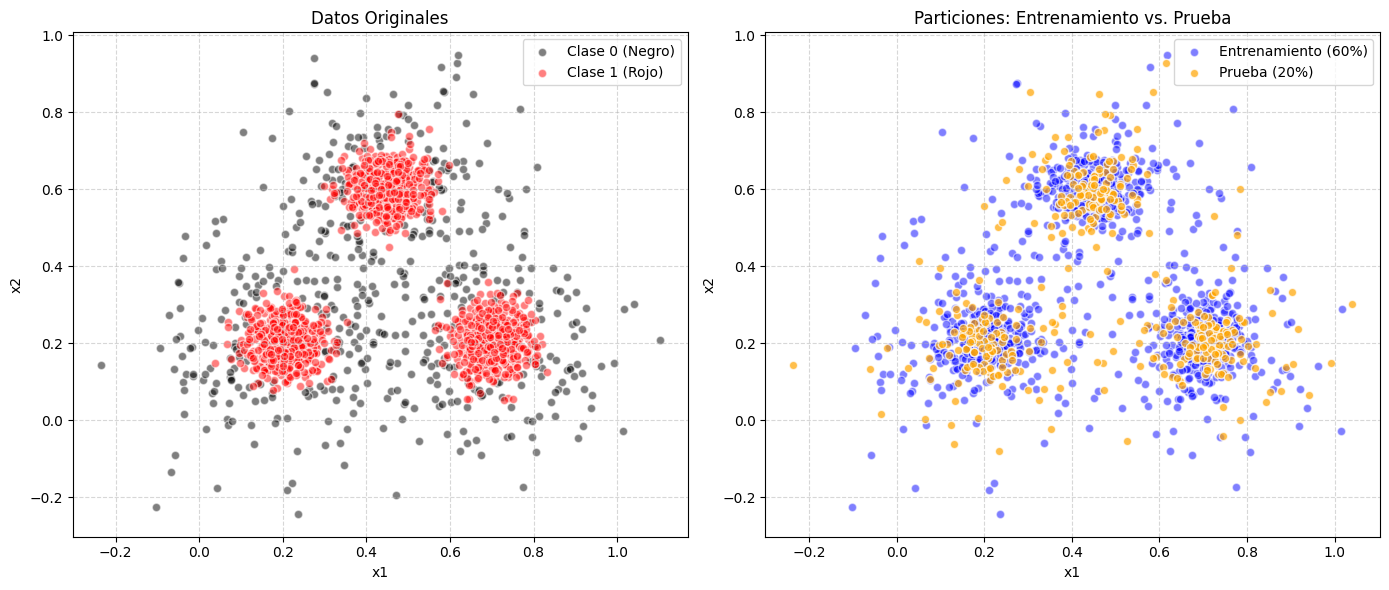

In [10]:
import matplotlib.pyplot as plt

# Configuración de estilo y subplots (dos figuras lado a lado)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Datos Originales
ax1 = axes[0]
ax1.scatter(X[y == 0][:, 0], X[y == 0][:, 1], color='black', alpha=0.5, label='Clase 0 (Negro)', edgecolors='w')
ax1.scatter(X[y == 1][:, 0], X[y == 1][:, 1], color='red', alpha=0.5, label='Clase 1 (Rojo)', edgecolors='w')
ax1.set_title("Datos Originales")
ax1.set_xlabel("x1")
ax1.set_ylabel("x2")
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# 2. Particiones de Entrenamiento y Prueba
ax2 = axes[1]
ax2.scatter(X_train[:, 0], X_train[:, 1], color='blue', alpha=0.5, label='Entrenamiento (60%)', edgecolors='w')
ax2.scatter(X_test[:, 0], X_test[:, 1], color='orange', alpha=0.7, label='Prueba (20%)', edgecolors='w')
ax2.set_title("Particiones: Entrenamiento vs. Prueba")
ax2.set_xlabel("x1")
ax2.set_ylabel("x2")
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## 3. Modelo y métricas

Cada MLP tiene dos entradas, una capa oculta de 30 neuronas y una salida binaria.
La activación elegida afecta la capa oculta; la salida de clasificación binaria sigue siendo logística.
Con `identity`, la composición de capas afines produce una frontera lineal, aunque haya 30 neuronas ocultas.

Todos los modelos usan el mismo optimizador L-BFGS, regularización, tolerancia y límite de iteraciones.
L-BFGS no usa minilotes; `max_iter` es un máximo de iteraciones del optimizador.
Cada `Pipeline` ajusta el escalador exclusivamente con entrenamiento para evitar filtración de información.
El objetivo de `MLPClassifier` es la pérdida logarítmica con regularización L2, no el error cuadrático de salida.

Métricas principales:
- **Accuracy**: proporción total de aciertos.
- **Recall negro**: proporción de puntos negros reconocidos; evita ocultar el fallo sobre la clase minoritaria.
- **Balanced accuracy**: promedio del recall de ambas clases.
- **F1 macro**: promedio del F1 de ambas clases.
- **Kappa**: acuerdo corregido por el esperado a partir de los marginales.
- **Log loss** y **Brier**: calidad de las probabilidades; valores menores son mejores.

El Brier binario se calcula como $\frac{1}{n}\sum_i (p_i-y_i)^2$, donde $p_i=P(y_i=1\mid x_i)$.
Los valores de `predict_proba` son estimaciones, no una garantía de calibración.


### 3.1. L-BFGS: cómo se ajustan los pesos

**L-BFGS** significa *Limited-memory Broyden–Fletcher–Goldfarb–Shanno*. Es un método de
optimización de la familia **cuasi-Newton**. Su tarea es modificar los pesos y sesgos para reducir
la función objetivo. No es una función de activación ni una métrica de evaluación.

Agrupemos todos los pesos y sesgos en un vector $\theta$. Durante el entrenamiento, el MLP
minimiza una función $J(\theta)$ que combina la pérdida logarítmica de entrenamiento y una
penalización L2 de los pesos, controlada por `alpha`. Backpropagation calcula el gradiente
$g_k=\nabla J(\theta_k)$; L-BFGS usa ese gradiente para decidir cómo actualizar los parámetros.

El descenso de gradiente convencional se representa como:

$$
\theta_{k+1}=\theta_k-\eta_k g_k.
$$

L-BFGS incorpora información aproximada de curvatura:

$$
d_k=-H_k g_k,\qquad \theta_{k+1}=\theta_k+\lambda_k d_k,
$$

donde $H_k$ aproxima la inversa de la matriz Hessiana y $\lambda_k$ es un paso determinado
mediante búsqueda en línea. La Hessiana describe cómo cambia el gradiente al mover los parámetros.

**Memoria limitada:** no se guarda la Hessiana completa. Se conservan algunos pares recientes
$s_k=\theta_{k+1}-\theta_k$ y $r_k=g_{k+1}-g_k$ para calcular la dirección de búsqueda.
Esto reduce el almacenamiento frente a BFGS completo. En la implementación del MLP se utiliza
el optimizador L-BFGS-B de SciPy; aquí no se imponen cotas explícitas a los pesos.

En este cuaderno:

| Parámetro | Interpretación con `solver="lbfgs"` |
| --- | --- |
| `max_iter=2000` | Máximo de iteraciones del optimizador; puede detenerse antes. |
| `max_fun=50000` | Límite de evaluaciones de la función objetivo; una iteración puede requerir varias. |
| `tol=1e-6` | Tolerancia asociada al criterio de convergencia. |
| `alpha=1e-4` | Intensidad de la regularización L2. |
| `random_state=42` | Controla la inicialización aleatoria del MLP. |

L-BFGS calcula el objetivo y el gradiente con el conjunto completo de entrenamiento; no usa los
minilotes de Adam o SGD. `learning_rate_init` no controla su paso y `batch_size` no se utiliza
con este solver. El escalado ayuda a evitar diferencias grandes entre las escalas de las variables.

La pérdida del MLP es no convexa: L-BFGS **no garantiza encontrar el mínimo global**.
Además, ReLU tiene puntos no diferenciables, de modo que las garantías de optimización suave
no se trasladan directamente a todos los modelos de esta comparación. Las advertencias se conservan
en la tabla para discutir la calidad de la optimización.


### 3.2. Log Loss: penalización de probabilidades equivocadas

Para cada observación, $y_i\in\{0,1\}$ es la clase verdadera y $p_i$ es la probabilidad estimada
de la clase roja: $p_i=P(y_i=1\mid x_i)$. La pérdida logarítmica binaria promedio es:

$$
\operatorname{LogLoss}=-\frac{1}{n}\sum_{i=1}^{n}
\left[y_i\ln(p_i)+(1-y_i)\ln(1-p_i)\right].
$$

Si el punto es rojo, su contribución es $-\ln(p_i)$; si es negro, es $-\ln(1-p_i)$.
Se usa el logaritmo natural. **Menor es mejor**: el valor ideal es 0 y la pérdida no tiene
una cota superior finita. En los casos límite se usa la interpretación por continuidad;
asignar probabilidad cero a la clase verdadera produce pérdida infinita en teoría.

Para un punto verdaderamente rojo:

| Probabilidad roja $p_i$ | Log Loss individual | Interpretación |
| --- | ---: | --- |
| 0,90 | 0,1054 | Predicción correcta con confianza alta. |
| 0,60 | 0,5108 | Predicción correcta con confianza moderada. |
| 0,10 | 2,3026 | Predicción equivocada y confiada. |
| 0,01 | 4,6052 | Error con confianza todavía mayor. |

Con umbral 0,5, tanto 0,90 como 0,60 predicen rojo y cuentan igual para accuracy.
Log Loss distingue la confianza asignada. Penaliza especialmente los errores muy seguros.

En `evaluar`, `log_loss(etiquetas, probabilidades, labels=clases)` recibe las probabilidades
de **ambas clases**, en el orden de `classes_`. No debe recibir las etiquetas duras de `predict`.
Scikit-learn limita numéricamente las probabilidades extremas para evitar logaritmos de cero;
por eso la referencia mayoritaria tiene una pérdida grande pero finita.

**Entrenamiento frente a evaluación:** la columna `Log loss` de la tabla se calcula en validación
o prueba y no incluye la penalización L2. No debe confundirse con el objetivo regularizado que
minimiza L-BFGS durante el entrenamiento.


### 3.3. Brier: error cuadrático de las probabilidades

Para este problema binario se utiliza la siguiente convención:

$$
\operatorname{Brier}=\frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)^2.
$$

Es el promedio de la distancia cuadrática entre la probabilidad de la clase roja y su indicador
verdadero. **Menor es mejor** y el resultado pertenece a $[0,1]$. El valor ideal es 0.
No es el error cuadrático de coordenadas ni el porcentaje de clasificaciones incorrectas.

Para el mismo punto rojo de los ejemplos anteriores ($y_i=1$):

| Probabilidad roja $p_i$ | Cálculo | Brier individual |
| --- | --- | ---: |
| 0,90 | $(0,90-1)^2$ | 0,0100 |
| 0,60 | $(0,60-1)^2$ | 0,1600 |
| 0,10 | $(0,10-1)^2$ | 0,8100 |
| 0,01 | $(0,01-1)^2$ | 0,9801 |

Si el punto es negro ($y_i=0$), la contribución es $p_i^2$: asignarle 0,10 de probabilidad roja
produce un Brier de 0,01.

En `evaluar`, `brier_score_loss(etiquetas, p_rojo)` recibe **una sola columna**: la probabilidad
de la clase 1. Esta es la convención binaria en escala $[0,1]$; sumar los errores cuadrados
de las dos columnas sin dividir entre dos daría el doble del valor mostrado aquí.

### 3.4. Cómo interpretar ambas métricas en este conjunto

| Aspecto | Log Loss | Brier binario |
| --- | --- | --- |
| Resultado ideal | 0 | 0 |
| Intervalo teórico | $[0,+\infty)$ | $[0,1]$ |
| Error muy confiado | Puede aumentar sin límite. | Su contribución se aproxima a 1. |
| Qué evalúa | Probabilidad asignada a la clase verdadera. | Error cuadrático de la probabilidad. |

No se comparan directamente sus valores numéricos entre sí: se compara la misma métrica entre
modelos sobre la misma partición. Ambas evalúan probabilidades y reflejan tanto calibración como
capacidad para distinguir clases; un valor bajo, por sí solo, no demuestra calibración perfecta.

Para una partición con 75 % rojos y 25 % negros:

- Predecir **probabilidad roja 0,75 para todos** da Log Loss aproximada de **0,5623** y Brier de **0,1875**.
- Predecir **probabilidad roja 1 para todos**, como la referencia de clase mayoritaria, da Brier de
  **0,25** y Log Loss teóricamente infinita, aunque conserva 75 % de accuracy.

Esto muestra por qué una referencia con probabilidades y una referencia de etiquetas duras
no son equivalentes, aun cuando ambas predigan siempre rojo con umbral 0,5.
Las métricas probabilísticas se complementan con balanced accuracy y recall negro para examinar
el desempeño de la clase minoritaria.

En este cuaderno, la **balanced accuracy de validación** decide la selección y Log Loss solo
resuelve empates. Brier se informa para analizar las probabilidades; no interviene en esa regla.


In [4]:
def evaluar(modelo, entradas, etiquetas):
    pred = modelo.predict(entradas)
    clases = np.asarray(modelo.classes_)
    probabilidades = modelo.predict_proba(entradas)
    columna_rojo = int(np.flatnonzero(clases == 1)[0])
    p_rojo = probabilidades[:, columna_rojo]
    return {
        "Accuracy": accuracy_score(etiquetas, pred),
        "Balanced accuracy": balanced_accuracy_score(etiquetas, pred),
        "Recall negro": recall_score(etiquetas, pred, pos_label=0, zero_division=0),
        "Recall rojo": recall_score(etiquetas, pred, pos_label=1, zero_division=0),
        "F1 macro": f1_score(etiquetas, pred, average="macro", zero_division=0),
        "Kappa": cohen_kappa_score(etiquetas, pred),
        "Log loss": log_loss(etiquetas, probabilidades, labels=clases),
        "Brier": brier_score_loss(etiquetas, p_rojo),
    }

def construir_mlp(activacion):
    return Pipeline([
        ("escala", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=(30,), activation=activacion,
                              solver="lbfgs", alpha=1e-4, tol=1e-6,
                              max_iter=2000, max_fun=50000, random_state=SEMILLA)),
    ])


## 4. Referencia de clase mayoritaria

Un modelo que siempre predice rojo alcanza 75 % de accuracy en estas particiones, pero su recall
para la clase negra es cero y su balanced accuracy es 50 %. Es la referencia mínima para interpretar el MLP.
La pérdida logarítmica de esta referencia puede ser muy alta porque asigna probabilidad cero a la clase negra.


In [5]:
referencia = DummyClassifier(strategy="most_frequent")
referencia.fit(X_train, y_train)
print("Referencia en validación:")
print(pd.Series(evaluar(referencia, X_val, y_val)).round(4).to_string())


Referencia en validación:
Accuracy             0.7500
Balanced accuracy    0.5000
Recall negro         0.0000
Recall rojo          1.0000
F1 macro             0.4286
Kappa                0.0000
Log loss             9.0109
Brier                0.2500


## 5. Comparación controlada en validación

Solo varía la activación oculta: `identity`, `logistic`, `tanh` y `relu`.
Se registra el desempeño en entrenamiento y validación, el tiempo y las advertencias.
Una advertencia de convergencia requiere revisar la optimización; tampoco debe suponerse que
la ausencia de advertencias garantiza el mejor mínimo o una buena generalización.

Una sola semilla sirve como demostración controlada. Para afirmar superioridad general sería necesario
repetir el experimento con varias particiones e inicializaciones, sin usar la prueba para elegirlas.


In [6]:
modelos, filas, avisos_por_modelo = {}, [], {}
for activacion in ["identity", "logistic", "tanh", "relu"]:
    modelo = construir_mlp(activacion)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_train, y_train)
    segundos = time.perf_counter() - inicio
    mensajes = [str(a.message) for a in avisos if issubclass(a.category, ConvergenceWarning)]
    otros = [a for a in avisos if not issubclass(a.category, ConvergenceWarning)]
    for aviso in otros:
        warnings.warn(str(aviso.message), aviso.category)
    entrenamiento = evaluar(modelo, X_train, y_train)
    validacion = evaluar(modelo, X_val, y_val)
    filas.append({"Activación": activacion,
                  "Accuracy train": entrenamiento["Accuracy"],
                  "Balanced train": entrenamiento["Balanced accuracy"],
                  **validacion, "Iteraciones": modelo.named_steps["mlp"].n_iter_,
                  "Aviso convergencia": bool(mensajes), "Segundos": segundos})
    modelos[activacion] = modelo
    avisos_por_modelo[activacion] = mensajes
    print(f"Entrenado: {activacion}; iteraciones: {modelo.named_steps['mlp'].n_iter_}; avisos: {len(mensajes)}")

resultados = pd.DataFrame(filas).set_index("Activación")
print("\nMétricas de validación (salvo las columnas train):")
print(resultados.round(4).to_string())
for activacion, mensajes in avisos_por_modelo.items():
    for mensaje in mensajes:
        print(f"\nAdvertencia de {activacion}: {mensaje}")


Entrenado: identity; iteraciones: 7; avisos: 0
Entrenado: logistic; iteraciones: 2000; avisos: 1
Entrenado: tanh; iteraciones: 2000; avisos: 1
Entrenado: relu; iteraciones: 261; avisos: 0

Métricas de validación (salvo las columnas train):
            Accuracy train  Balanced train  Accuracy  Balanced accuracy  Recall negro  Recall rojo  F1 macro   Kappa  Log loss   Brier  Iteraciones  Aviso convergencia  Segundos
Activación                                                                                                                                                                       
identity            0.7500          0.5000    0.7500              0.500          0.00         1.00    0.4286  0.0000    0.5635  0.1879            7               False    0.0641
logistic            0.9825          0.9761    0.9275              0.925          0.92         0.93    0.9072  0.8147    1.1731  0.0638         2000                True   13.5820
tanh                0.9892          0.9883    0.

## 6. Selección del modelo

Regla fijada antes de consultar la prueba: mayor balanced accuracy de validación; en caso de empate,
menor log loss; si persiste el empate, orden alfabético de la activación.
Se incluyen los modelos con advertencias, pero se informa si el elegido tiene alguna: su optimización
podría necesitar revisión. La regla no cambia según el resultado de prueba.


In [7]:
ranking = resultados.reset_index().sort_values(
    ["Balanced accuracy", "Log loss", "Activación"],
    ascending=[False, True, True], kind="mergesort")
mejor_activacion = ranking.iloc[0]["Activación"]
mejor_modelo = modelos[mejor_activacion]
print("Activación seleccionada:", mejor_activacion)
print("Balanced accuracy de validación:", round(ranking.iloc[0]["Balanced accuracy"], 4))
if avisos_por_modelo[mejor_activacion]:
    print("ATENCIÓN: el modelo seleccionado tiene advertencias de convergencia.")


Activación seleccionada: relu
Balanced accuracy de validación: 0.925


## 7. Evaluación final en prueba

Evaluamos el modelo seleccionado y la referencia sobre los mismos 400 casos de prueba.
Conservamos el modelo entrenado en el 60 % original: no se vuelve a ajustar con validación.
La matriz usa filas para las clases verdaderas y columnas para las clases predichas, en orden negro, rojo.


In [8]:
comparacion_test = pd.DataFrame({
    "Referencia mayoritaria": evaluar(referencia, X_test, y_test),
    "MLP seleccionado": evaluar(mejor_modelo, X_test, y_test),
}).T
print(comparacion_test.round(4).to_string())
y_pred_test = mejor_modelo.predict(X_test)
matriz = confusion_matrix(y_test, y_pred_test, labels=[0, 1])
print("\nMatriz de confusión del MLP:")
print(pd.DataFrame(matriz,
                   index=["Real negro (0)", "Real rojo (1)"],
                   columns=["Predicho negro (0)", "Predicho rojo (1)"]).to_string())
print("\nInforme por clase:")
print(classification_report(y_test, y_pred_test, labels=[0, 1],
                            target_names=["Negro", "Rojo"], digits=4, zero_division=0))


                        Accuracy  Balanced accuracy  Recall negro  Recall rojo  F1 macro   Kappa  Log loss   Brier
Referencia mayoritaria    0.7500             0.5000          0.00       1.0000    0.4286  0.0000    9.0109  0.2500
MLP seleccionado          0.9075             0.8817          0.83       0.9333    0.8779  0.7558    0.2572  0.0703

Matriz de confusión del MLP:
                Predicho negro (0)  Predicho rojo (1)
Real negro (0)                  83                 17
Real rojo (1)                   20                280

Informe por clase:
              precision    recall  f1-score   support

       Negro     0.8058    0.8300    0.8177       100
        Rojo     0.9428    0.9333    0.9380       300

    accuracy                         0.9075       400
   macro avg     0.8743    0.8817    0.8779       400
weighted avg     0.9085    0.9075    0.9080       400



## 8. Inferencia y preguntas para la clase

La siguiente celda usa cinco observaciones ya existentes del conjunto de prueba.
Las probabilidades siguen el orden de `classes_`; no se supone que una columna represente una clase por su posición.

1. ¿Por qué 75 % de accuracy resulta insuficiente para juzgar este problema?
2. ¿Puede una red con activación identidad representar tres regiones cerradas separadas?
3. ¿Qué indica una diferencia grande entre desempeño de entrenamiento y validación?
4. ¿Por qué las distribuciones pueden solaparse aunque se rechacen negros cerca de los centros?
5. ¿Qué diferencia hay entre acertar la etiqueta y asignarle una probabilidad adecuada?
6. ¿Por qué no se debe escoger la activación después de mirar los resultados de prueba?

Este cuaderno no busca una configuración óptima global. Aísla la activación para estudiar su efecto
sobre el mismo problema, con una evaluación independiente. No se exige accuracy perfecto, porque las
clases se generan mediante distribuciones que se solapan.


In [9]:
indices_clase = [int(np.flatnonzero(y_test == c)[0]) for c in [0, 1]]
seleccion = indices_clase + [i for i in range(len(y_test)) if i not in indices_clase][:3]
muestra = X_test[seleccion]
probas = mejor_modelo.predict_proba(muestra)
tabla = pd.DataFrame(muestra, columns=["x1", "x2"])
tabla["Clase verdadera"] = y_test[seleccion]
tabla["Clase predicha"] = mejor_modelo.predict(muestra)
for j, clase in enumerate(mejor_modelo.classes_):
    tabla[f"P(clase={clase})"] = probas[:, j]
print(tabla.round(4).to_string(index=False))


    x1     x2  Clase verdadera  Clase predicha  P(clase=0)  P(clase=1)
0.6308 0.3135                0               1      0.3290      0.6710
0.4412 0.6831                1               1      0.0169      0.9831
0.6291 0.1120                1               1      0.2547      0.7453
0.4803 0.5908                1               1      0.0026      0.9974
0.7257 0.1870                1               1      0.0014      0.9986


## Referencias

- [MLPClassifier: parámetros, atributos y métodos](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).
- [Redes neuronales supervisadas](https://scikit-learn.org/stable/modules/neural_networks_supervised.html).
- [Separación de datos y prevención de filtraciones](https://scikit-learn.org/stable/common_pitfalls.html).

La semilla fija facilita la reproducción en el mismo entorno. Las versiones de las dependencias pueden
producir pequeñas diferencias numéricas; sus versiones se imprimen al inicio.

- [SciPy: optimización L-BFGS-B](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-lbfgsb.html).
- [Definición de Log Loss](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html).
- [Definición de Brier score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.brier_score_loss.html).
